# Hinglish Sarcasm Detection — Complete Notebook
**Dataset:** `mananjen/hinglish_sarcasm_dataset` → `human_labelled_features.csv`

This notebook covers data download, audit, label cleaning, duplicate checks, EDA, stratified train/validation/test split, TF-IDF + Logistic Regression, test evaluation, error analysis, optional transformer fine-tuning, and annotation-agreement support.

**Research integrity:** use `human_labelled` as the target, not `ai_labelled`. Verify the repository license and suitability before reuse/redistribution. Comments may contain offensive or sensitive content. The repository has one final human label per comment; Cohen's kappa for two annotators must be calculated from a separately collected double-annotated sample.

## 0. Install dependencies

In [ ]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn scipy joblib requests

## 1. Imports and configuration

In [ ]:
import os, re, json, random, sys, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
OUT = Path("hinglish_sarcasm_outputs")
OUT.mkdir(exist_ok=True)
DATA_URL = "https://raw.githubusercontent.com/mananjen/hinglish_sarcasm_dataset/main/human_labelled_features.csv"
print("Python:", sys.version, "| Platform:", platform.platform())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] | Platform: Linux-6.6.122+-x86_64-with-glibc2.39


## 2. Download and load the human-labelled CSV

In [ ]:
# If download fails, manually download the CSV from:
# https://github.com/mananjen/hinglish_sarcasm_dataset/blob/main/human_labelled_features.csv
LOCAL_CSV = None  # Example: "/content/human_labelled_features.csv"

raw_path = OUT / "human_labelled_features.csv"
if LOCAL_CSV:
    raw_path = Path(LOCAL_CSV)
else:
    response = requests.get(DATA_URL, timeout=60)
    response.raise_for_status()
    raw_path.write_bytes(response.content)

raw = pd.read_csv(raw_path, encoding="utf-8", low_memory=False)
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())

Raw shape: (8885, 5)
Columns: ['comment', 'human_labelled', 'ai_labelled', 'emoji_present', 'hindi_pct']


,comment,human_labelled,ai_labelled,emoji_present,hindi_pct
0,Lo or kro Rahul Gandhi face_with_tears_of_joy ...,sarcastic,sarcastic,yes,19.05
1,eesko krte time kitno ne condom nhi lagaya,non-sarcastic,sarcastic,no,78.57
2,"kaam kam, dialogues zyada",sarcastic,sarcastic,no,57.14
3,sudhanshu trivedi ke samne koi bolsakta hai ky...,non-sarcastic,sarcastic,yes,30.56
4,nujhe to rona a raha hai ab bas kar bhenji var...,non-sarcastic,sarcastic,no,100.00


In [ ]:
required = {"comment", "human_labelled"}
if not required.issubset(raw.columns):
    raise ValueError(f"Expected {required}; got {raw.columns.tolist()}")

print("Raw human-label values:")
display(raw["human_labelled"].astype("string").str.strip().str.lower().value_counts(dropna=False).to_frame("count"))
print("Missing comments:", raw["comment"].isna().sum())

Raw human-label values:


,count
human_labelled,
non-sarcastic,4768
sarcastic,3737
non_sarcastic,377
error,3


Missing comments: 0


## 3. Clean schema and normalize known label variants

In [ ]:
df = raw.copy()
df["text"] = df["comment"].fillna("").astype(str)
df["label_raw"] = df["human_labelled"].astype("string").str.strip().str.lower()
label_map = {
    "sarcastic": "Sarcastic",
    "non-sarcastic": "Sincere",
    "non_sarcastic": "Sincere",
    "non sarcastic": "Sincere",
}
df["label"] = df["label_raw"].map(label_map)
df["text_for_dedup"] = (
    df["text"].str.normalize("NFKC").str.lower()
      .str.replace(r"\s+", " ", regex=True).str.strip()
)
bad_label = df["label"].isna()
empty_text = df["text_for_dedup"].eq("")
print("Unknown/missing labels:", int(bad_label.sum()))
print("Empty comments:", int(empty_text.sum()))
if bad_label.any():
    display(df.loc[bad_label, "label_raw"].value_counts(dropna=False).to_frame("count"))
    df.loc[bad_label].to_csv(OUT / "rows_for_label_review.csv", index=False)

clean = df.loc[~bad_label & ~empty_text].copy().reset_index(drop=True)
print("Usable rows before dedup:", len(clean))

Unknown/missing labels: 3
Empty comments: 0


,count
label_raw,
error,3


Usable rows before dedup: 8882


## 4. Duplicate and conflicting-label checks

In [ ]:
dup_mask = clean.duplicated("text_for_dedup", keep=False)
print("Rows in exact duplicate groups:", int(dup_mask.sum()))
print("Duplicated normalized comments:", int(clean.loc[dup_mask, "text_for_dedup"].nunique()))

n_labels = clean.groupby("text_for_dedup")["label"].nunique()
conflicting_texts = n_labels[n_labels > 1].index
print("Texts with conflicting labels:", len(conflicting_texts))
if len(conflicting_texts):
    conflicts = clean[clean["text_for_dedup"].isin(conflicting_texts)]
    display(conflicts[["text", "label", "label_raw"]].head(30))
    conflicts.to_csv(OUT / "conflicting_duplicate_labels.csv", index=False)

# Conservative policy: hold conflicting duplicate groups out for manual review;
# then keep one occurrence of each remaining normalized text.
usable = clean[~clean["text_for_dedup"].isin(conflicting_texts)].copy()
dedup = usable.drop_duplicates("text_for_dedup", keep="first").reset_index(drop=True)
print("Rows after conflict-group exclusion:", len(usable))
print("Rows after deduplication:", len(dedup))

Rows in exact duplicate groups: 576
Duplicated normalized comments: 182
Texts with conflicting labels: 24


,text,label,label_raw
116,rahul gandhi vada kiye the ki unki sarkar bane...,Sincere,non-sarcastic
292,rolling_on_the_floor_laughing rolling_on_the_f...,Sincere,non-sarcastic
399,Dhruv Rathee cross_mark Aam admi party worker ...,Sarcastic,sarcastic
571,rolling_on_the_floor_laughing rolling_on_the_f...,Sincere,non-sarcastic
916,German Shepherd for a reason face_with_tears_o...,Sincere,non_sarcastic
966,tu bhi marega owaisi ruk tera beta b ram ram b...,Sarcastic,sarcastic
1063,rolling_on_the_floor_laughing rolling_on_the_f...,Sincere,non-sarcastic
1072,rolling_on_the_floor_laughing rolling_on_the_f...,Sincere,non-sarcastic
1199,dhuru rathee ke kitne bap skull moai moai skul...,Sincere,non-sarcastic
1310,rolling_on_the_floor_laughing rolling_on_the_f...,Sincere,non-sarcastic


Rows after conflict-group exclusion: 8817
Rows after deduplication: 8464


In [ ]:
audit = {
    "audit_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "raw_rows": int(len(raw)),
    "raw_columns": raw.columns.tolist(),
    "unknown_or_missing_labels": int(bad_label.sum()),
    "empty_text_rows": int(empty_text.sum()),
    "conflicting_duplicate_texts": int(len(conflicting_texts)),
    "final_rows": int(len(dedup)),
    "final_label_counts": {str(k): int(v) for k, v in dedup["label"].value_counts().items()},
}
(OUT / "quality_audit_report.json").write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(audit, indent=2, ensure_ascii=False))

{
  "audit_timestamp_utc": "2026-10-25T17:42:22.626979+00:00",
  "raw_rows": 8885,
  "raw_columns": [
    "comment",
    "human_labelled",
    "ai_labelled",
    "emoji_present",
    "hindi_pct"
  ],
  "unknown_or_missing_labels": 3,
  "empty_text_rows": 0,
  "conflicting_duplicate_texts": 24,
  "final_rows": 8464,
  "final_label_counts": {
    "Sincere": 4819,
    "Sarcastic": 3645
  }
}


## 5. Exploratory data analysis

,count
label,
Sincere,4819
Sarcastic,3645


,percent
label,
Sincere,56.94
Sarcastic,43.06


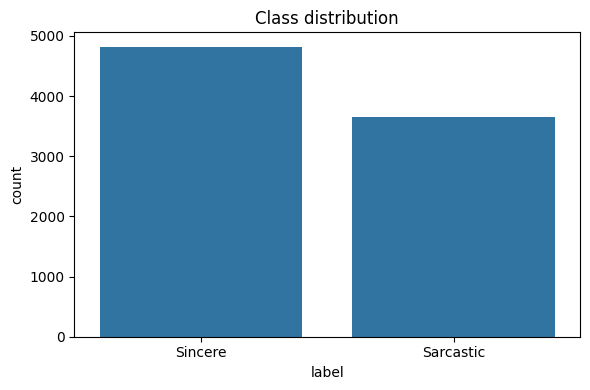

char_count                                                 \
               count   mean    std   min   25%   50%    75%     max   
label                                                                 
Sarcastic     3645.0  92.83  86.87  13.0  48.0  74.0  108.0  1532.0   
Sincere       4819.0  90.69  97.37   4.0  47.0  67.0  103.0  2625.0   

          word_count                                             
               count   mean    std  min  25%   50%   75%    max  
label                                                            
Sarcastic     3645.0  13.60  12.13  3.0  8.0  11.0  15.0  242.0  
Sincere       4819.0  12.15  13.37  2.0  7.0   9.0  13.0  425.0

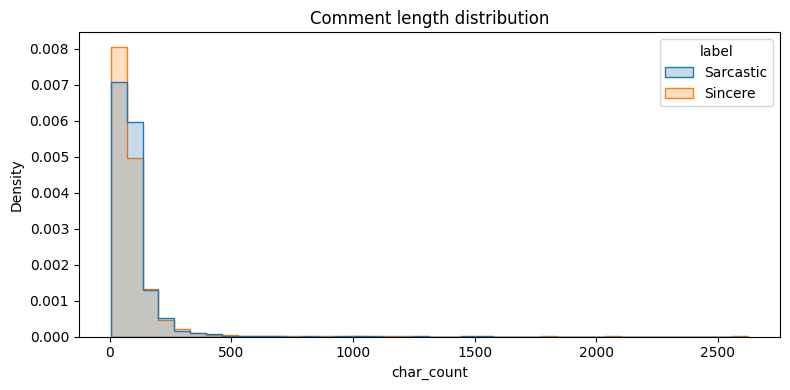


 emoji_present


,count
emoji_present,
no,5425
yes,3039



 hindi_pct


,count
hindi_pct,
0.00,1151
100.00,716
50.00,175
66.67,115
75.00,97
33.33,89
80.00,79
85.71,64
83.33,64



 ai_labelled


,count
ai_labelled,
sarcastic,7317
non-sarcastic,1128
unknown,19


In [ ]:
display(dedup["label"].value_counts().rename_axis("label").to_frame("count"))
display((dedup["label"].value_counts(normalize=True)*100).round(2).rename("percent").to_frame())
plt.figure(figsize=(6,4))
sns.countplot(data=dedup, x="label", order=["Sincere", "Sarcastic"])
plt.title("Class distribution"); plt.tight_layout(); plt.show()

dedup["char_count"] = dedup["text"].str.len()
dedup["word_count"] = dedup["text"].str.split().str.len()
display(dedup.groupby("label")[["char_count", "word_count"]].describe().round(2))
plt.figure(figsize=(8,4))
sns.histplot(data=dedup, x="char_count", hue="label", bins=40, element="step",
             stat="density", common_norm=False)
plt.title("Comment length distribution"); plt.tight_layout(); plt.show()

for col in ["emoji_present", "hindi_pct", "ai_labelled"]:
    if col in dedup.columns:
        print("\n", col)
        display(dedup[col].value_counts(dropna=False).head(20).to_frame("count"))

## 6. Train / validation / test split

In [ ]:
# 80% train, 10% validation, 10% test. Exact duplicate groups have already been handled.
train_df, temp_df = train_test_split(
    dedup, test_size=0.20, random_state=SEED, stratify=dedup["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(name, part.shape, part["label"].value_counts(normalize=True).round(3).to_dict())

assert set(train_df.text_for_dedup).isdisjoint(set(val_df.text_for_dedup))
assert set(train_df.text_for_dedup).isdisjoint(set(test_df.text_for_dedup))
assert set(val_df.text_for_dedup).isdisjoint(set(test_df.text_for_dedup))
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    part.to_csv(OUT / f"{name}.csv", index=False)

train (6771, 11) {'Sincere': 0.569, 'Sarcastic': 0.431}
validation (846, 11) {'Sincere': 0.57, 'Sarcastic': 0.43}
test (847, 11) {'Sincere': 0.569, 'Sarcastic': 0.431}


## 7. Baseline: word + character TF-IDF and Logistic Regression


=== TF-IDF + Logistic Regression — validation ===
Accuracy: 0.6478
Macro-F1: 0.6452
              precision    recall  f1-score   support

     Sincere       0.71      0.64      0.68       482
   Sarcastic       0.58      0.65      0.61       364

    accuracy                           0.65       846
   macro avg       0.65      0.65      0.65       846
weighted avg       0.65      0.65      0.65       846



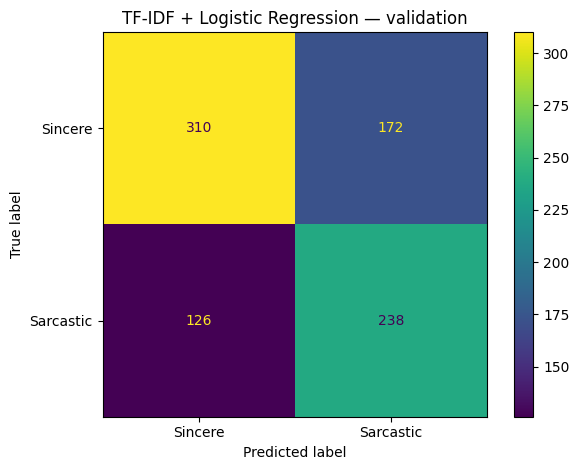

{'accuracy': 0.6477541371158393, 'macro_f1': 0.6451841718599585, 'weighted_f1': 0.6493960593626519}


In [ ]:
def evaluate(y_true, y_pred, title):
    print("\n===", title, "===")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print(classification_report(y_true, y_pred, labels=["Sincere","Sarcastic"], zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=["Sincere","Sarcastic"])
    ConfusionMatrixDisplay(cm, display_labels=["Sincere","Sarcastic"]).plot(values_format="d")
    plt.title(title); plt.tight_layout(); plt.show()
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
            "weighted_f1": float(f1_score(y_true, y_pred, average="weighted"))}

baseline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2,
                                 max_features=150000, sublinear_tf=True,
                                 token_pattern=r"(?u)\b\w+\b")),
        ("char", TfidfVectorizer(analyzer="char", ngram_range=(3,5), min_df=2,
                                 max_features=200000, sublinear_tf=True)),
    ])),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
])

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val = val_df["text"], val_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

baseline.fit(X_train, y_train)
val_pred = baseline.predict(X_val)
val_metrics = evaluate(y_val, val_pred, "TF-IDF + Logistic Regression — validation")
print(val_metrics)

## 8. Held-out test evaluation


=== TF-IDF + Logistic Regression — test ===
Accuracy: 0.6517
Macro-F1: 0.6502
              precision    recall  f1-score   support

     Sincere       0.72      0.63      0.67       482
   Sarcastic       0.58      0.68      0.63       365

    accuracy                           0.65       847
   macro avg       0.65      0.66      0.65       847
weighted avg       0.66      0.65      0.65       847



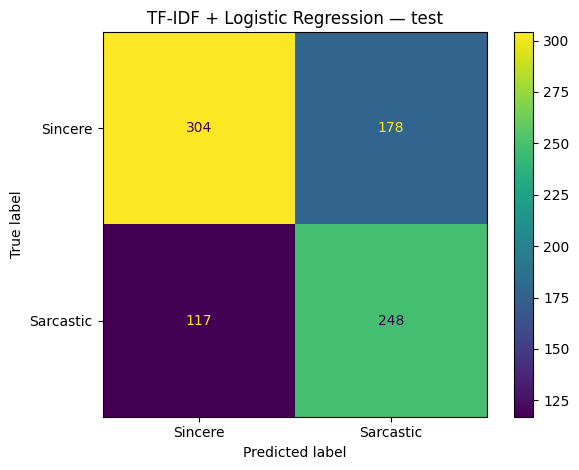

{'model': 'TF-IDF word+character n-grams + Logistic Regression', 'seed': 42, 'train_rows': 6771, 'validation_rows': 846, 'test_rows': 847, 'accuracy': 0.6517119244391971, 'macro_f1': 0.6501827732533639, 'weighted_f1': 0.6533776069809084}


In [ ]:
# Use the validation set for model decisions. Evaluate the test set once for final reporting.
test_pred = baseline.predict(X_test)
baseline_metrics = evaluate(y_test, test_pred, "TF-IDF + Logistic Regression — test")
baseline_results = {
    "model": "TF-IDF word+character n-grams + Logistic Regression",
    "seed": SEED,
    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    **baseline_metrics
}
(OUT / "baseline_test_metrics.json").write_text(json.dumps(baseline_results, indent=2), encoding="utf-8")
print(baseline_results)

## 9. Error analysis

In [ ]:
errors = test_df[["text", "label"]].copy()
errors["prediction"] = test_pred
errors["confidence"] = baseline.predict_proba(X_test).max(axis=1)
errors["correct"] = errors["label"] == errors["prediction"]

print("False positives (Sincere predicted as Sarcastic):")
display(errors[(errors.label=="Sincere") & (errors.prediction=="Sarcastic")].sort_values("confidence", ascending=False).head(25))
print("False negatives (Sarcastic predicted as Sincere):")
display(errors[(errors.label=="Sarcastic") & (errors.prediction=="Sincere")].sort_values("confidence", ascending=False).head(25))
errors.loc[~errors.correct].to_csv(OUT / "baseline_test_errors.csv", index=False)

False positives (Sincere predicted as Sarcastic):


,text,label,prediction,confidence,correct
3124,nain apne aulad ko ye bhi batunga ka tum log d...,Sincere,Sarcastic,0.883804,False
6354,brother apko pta hi nhi ke tax kaha lagta jaha...,Sincere,Sarcastic,0.882950,False
8179,fir bhi koy hindu ese hi vot karega.sudhar jao...,Sincere,Sarcastic,0.855396,False
4302,Congress wale abhi PM nhi bane hai,Sincere,Sarcastic,0.850945,False
3694,aabe nusalman ki jat madrachod apni man chod l...,Sincere,Sarcastic,0.832219,False
4849,Bheem vale kaha gaye apni ray do face_with_tea...,Sincere,Sarcastic,0.828490,False
2309,tumhari ma.... c...... liye lawrence bisnoi ha...,Sincere,Sarcastic,0.826158,False
6993,yeh sb ki sb dekh lo kon haii clown_face,Sincere,Sarcastic,0.822727,False
322,bhai sab log bjp ko vote dena yahan per sab lo...,Sincere,Sarcastic,0.818900,False
8099,face_with_tears_of_joy face_with_tears_of_joy ...,Sincere,Sarcastic,0.811402,False


False negatives (Sarcastic predicted as Sincere):


,text,label,prediction,confidence,correct
4788,green_heart green_heart babari nahi bhul hi ja...,Sarcastic,Sincere,0.851373,False
3955,rolling_on_the_floor_laughing rolling_on_the_f...,Sarcastic,Sincere,0.840725,False
2239,bhai nai bhi up se hi lekin dogla ni hu jay sh...,Sarcastic,Sincere,0.830539,False
5933,chaachaa neharoo kee maadara ....... hai enrag...,Sarcastic,Sincere,0.812509,False
2906,General knowledge ka hacker hai bhai hacker fi...,Sarcastic,Sincere,0.811911,False
2717,Another reason why India is not for beginners ...,Sarcastic,Sincere,0.811210,False
6052,Nikal be lawdi abbu ke sath sone waali allah k...,Sarcastic,Sincere,0.806619,False
4882,Pata chal gya muslimo ka asliyat enraged_face ...,Sarcastic,Sincere,0.802489,False
7644,Pelvish k wqt kha the jb cm bhi meetup m gya t...,Sarcastic,Sincere,0.791090,False
2663,jai shri ram triangular_flag triangular_flag b...,Sarcastic,Sincere,0.789695,False


## 10. Double annotation template and Cohen's kappa

The source file contains a single final `human_labelled` value, not two independent annotator labels. You cannot calculate your own inter-annotator agreement from that column. The following creates a sample for two annotators. They should label independently and must not see each other's responses.

In [ ]:
n_sample = min(200, len(dedup))
ann_template = dedup.sample(n=n_sample, random_state=SEED)[["text"]].copy()
ann_template.insert(0, "sample_id", [f"A{i:04d}" for i in range(1, len(ann_template)+1)])
ann_template["annotator_1"] = ""
ann_template["annotator_2"] = ""
ann_template.to_csv(OUT / "double_annotation_template.csv", index=False)
print("Saved:", OUT / "double_annotation_template.csv")

Saved: hinglish_sarcasm_outputs/double_annotation_template.csv


In [ ]:
# After annotators complete the file, save it as:
# hinglish_sarcasm_outputs/double_annotation_completed.csv
ann_file = OUT / "double_annotation_completed.csv"
if ann_file.exists():
    ann = pd.read_csv(ann_file).dropna(subset=["annotator_1", "annotator_2"]).copy()
    valid = {"Sarcastic", "Sincere"}
    ann["annotator_1"] = ann["annotator_1"].astype(str).str.strip()
    ann["annotator_2"] = ann["annotator_2"].astype(str).str.strip()
    ann = ann[ann.annotator_1.isin(valid) & ann.annotator_2.isin(valid)]
    if len(ann):
        print("Items:", len(ann))
        print("Raw agreement:", round(float((ann.annotator_1 == ann.annotator_2).mean()), 4))
        print("Cohen's kappa:", round(float(cohen_kappa_score(
            ann.annotator_1, ann.annotator_2, labels=["Sincere","Sarcastic"])), 4))
    else:
        print("No valid completed annotation rows.")
else:
    print("Complete the template first, then rerun this cell.")

Complete the template first, then rerun this cell.


## 11. Optional transformer comparison (multilingual BERT)

This optional section fine-tunes `bert-base-multilingual-cased` on the same split. It requires extra dependencies and is best run with a GPU. This is a reasonable multilingual starting point, not a guarantee of optimal Romanized-Hinglish performance. Check the model card and license before use.

In [ ]:
%pip -q install transformers datasets accelerate

In [ ]:
RUN_TRANSFORMER = False  # Set True to run after installing dependencies; GPU recommended.
if RUN_TRANSFORMER:
    import torch
    from datasets import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
        TrainingArguments, Trainer, DataCollatorWithPadding)
    print("CUDA available:", torch.cuda.is_available())
else:
    print("Transformer training skipped. Set RUN_TRANSFORMER=True to run.")

Transformer training skipped. Set RUN_TRANSFORMER=True to run.


In [ ]:
if RUN_TRANSFORMER:
    MODEL_NAME = "bert-base-multilingual-cased"
    MAX_LENGTH = 128
    label2id = {"Sincere": 0, "Sarcastic": 1}
    id2label = {v:k for k,v in label2id.items()}
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    def make_ds(frame):
        out = frame[["text","label"]].copy()
        out["labels"] = out["label"].map(label2id).astype(int)
        ds = Dataset.from_pandas(out[["text","labels"]], preserve_index=False)
        return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LENGTH), batched=True)

    train_hf, val_hf, test_hf = map(make_ds, [train_df, val_df, test_df])
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, label2id=label2id, id2label=id2label
    )
    collator = DataCollatorWithPadding(tokenizer=tokenizer)

    def compute_metrics(p):
        logits, labels = p
        preds = np.argmax(logits, axis=-1)
        return {"accuracy": accuracy_score(labels, preds),
                "macro_f1": f1_score(labels, preds, average="macro"),
                "weighted_f1": f1_score(labels, preds, average="weighted")}

    args = TrainingArguments(
        output_dir=str(OUT / "mbert_checkpoints"),
        evaluation_strategy="epoch", save_strategy="epoch",
        learning_rate=2e-5, per_device_train_batch_size=16,
        per_device_eval_batch_size=32, num_train_epochs=3, weight_decay=0.01,
        load_best_model_at_end=True, metric_for_best_model="eval_macro_f1",
        greater_is_better=True, save_total_limit=2, logging_steps=50,
        seed=SEED, report_to="none"
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_hf,
        eval_dataset=val_hf, tokenizer=tokenizer, data_collator=collator,
        compute_metrics=compute_metrics)
    trainer.train()
    print(trainer.evaluate())

In [ ]:
if RUN_TRANSFORMER:
    pred_out = trainer.predict(test_hf)
    pred_ids = np.argmax(pred_out.predictions, axis=-1)
    transformer_pred = [id2label[int(i)] for i in pred_ids]
    transformer_metrics = evaluate(y_test.tolist(), transformer_pred, "Multilingual BERT — test")
    trainer.save_model(str(OUT / "multilingual_bert_final"))
    tokenizer.save_pretrained(str(OUT / "multilingual_bert_final"))
    (OUT / "transformer_test_metrics.json").write_text(
        json.dumps({"model": MODEL_NAME, **transformer_metrics}, indent=2), encoding="utf-8")

## 12. Save model, metrics, and cleaned dataset

In [ ]:
joblib.dump(baseline, OUT / "tfidf_logistic_regression.joblib")
dedup[[c for c in ["text","label","label_raw","emoji_present","hindi_pct","ai_labelled","text_for_dedup"]
       if c in dedup.columns]].to_csv(OUT / "cleaned_human_labelled_dataset.csv", index=False)

results = [baseline_results]
if (OUT / "transformer_test_metrics.json").exists():
    results.append(json.loads((OUT / "transformer_test_metrics.json").read_text(encoding="utf-8")))
pd.DataFrame(results).to_csv(OUT / "model_comparison.csv", index=False)
print("Artifacts:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size:,} bytes")

Artifacts:
baseline_test_errors.csv: 38,817 bytes
baseline_test_metrics.json: 255 bytes
cleaned_human_labelled_dataset.csv: 1,954,457 bytes
conflicting_duplicate_labels.csv: 25,472 bytes
double_annotation_template.csv: 22,479 bytes
human_labelled_features.csv: 1,141,167 bytes
model_comparison.csv: 203 bytes
quality_audit_report.json: 391 bytes
rows_for_label_review.csv: 1,081 bytes
test.csv: 301,562 bytes
tfidf_logistic_regression.joblib: 3,620,196 bytes
train.csv: 2,323,714 bytes
validation.csv: 288,718 bytes


## 13. Inference on new comments

In [ ]:
def predict_comments(comments, model=baseline):
    pred = model.predict(comments)
    probs = model.predict_proba(comments)
    classes = list(model.named_steps["classifier"].classes_)
    rows = []
    for text, label, p in zip(comments, pred, probs):
        rows.append({
            "text": text,
            "predicted_label": label,
            "confidence": float(np.max(p)),
            "probabilities": {classes[i]: float(p[i]) for i in range(len(classes))}
        })
    return pd.DataFrame(rows)

display(predict_comments([
    "Wah kya perfect planning hai, sab kuch late kar diya.",
    "Thank you yaar, tumne sach mein help ki."
]))

,text,predicted_label,confidence,probabilities
0,"Wah kya perfect planning hai, sab kuch late ka...",Sarcastic,0.851681,"{'Sarcastic': 0.8516807433165599, 'Sincere': 0..."
1,"Thank you yaar, tumne sach mein help ki.",Sincere,0.729305,"{'Sarcastic': 0.2706948963702124, 'Sincere': 0..."


## 14. Final reporting checklist

Before reporting results:
- Record dataset URL, access date, license, citation, and permitted use.
- Report raw and final row counts, unknown labels, duplicates, conflicting duplicate groups, and class balance.
- Report exact train/validation/test sizes and seed.
- Include accuracy, per-class precision/recall/F1, macro-F1, and confusion matrix.
- For transformers, record checkpoint, tokenizer, hyperparameters, versions, hardware, and training time.
- Report Cohen's kappa only after collecting independent labels from two annotators.
- Discuss limits: context is missing from standalone comments; code-mixing and spelling vary; labels may be biased; test performance may not generalize to other platforms.
- Keep synthetic examples separate and clearly marked. Do not claim they are real comments or silently mix them into the human-labelled corpus.

Repository citation (as provided in its README):
Manan Jain and Hemanth Nagulapalli. *Hinglish Sarcasm Detection Dataset* (2025).
https://github.com/mananjen/hinglish_sarcasm_dataset

In [ ]:
# 15. Additional Baselines, Ablations, and Majority Class Reference
majority_label = train_df["label"].mode()[0]
majority_preds = [majority_label] * len(y_test)

print("=== Majority Class Baseline ===")
print("Accuracy:", round(accuracy_score(y_test, majority_preds), 4))
print("Macro-F1:", round(f1_score(y_test, majority_preds, average='macro'), 4))

# Quick Feature Ablation
ablations = {
    "Word Only": Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2,
                                  max_features=150000, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
    ]),
    "Char Only": Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(3,5), min_df=2,
                                  max_features=200000, sublinear_tf=True)),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
    ])
}

for name, pipe in ablations.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    print(f"\n=== {name} Ablation Baseline ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Macro-F1:", round(f1_score(y_test, preds, average='macro'), 4))

=== Majority Class Baseline ===
Accuracy: 0.5691
Macro-F1: 0.3627

=== Word Only Ablation Baseline ===
Accuracy: 0.6434
Macro-F1: 0.6425

=== Char Only Ablation Baseline ===
Accuracy: 0.6269
Macro-F1: 0.6253
